# Notebook 01: Khám phá dữ liệu, Kiểm toán chất lượng & Tính sẵn có của đặc trưng (EDA & Data Audit)

**Đề tài:** Dự đoán khả năng khách hàng hủy đặt phòng khách sạn (Hotel Booking Cancellation Prediction)  
**Thời điểm dự đoán (Prediction Cutoff):** **Tại thời điểm xác nhận đặt phòng (Booking Confirmation)**  
**Dữ liệu đầu vào:** `raw/hotel_bookings.csv`  
**Đầu ra biểu đồ:** Lưu tự động tại `eda_figures/` (300 DPI) phục vụ báo cáo.

### Mục tiêu của Notebook 01
1. Kiểm toán tổng quan kích thước, kiểu dữ liệu, giá trị thiếu (missing values) và các bản ghi bất thường (record-level outlier investigation).
2. Phân tích **Identical Feature Fingerprint** (các bản ghi có cùng tổ hợp đặc trưng) — định lượng kích thước nhóm và tỷ lệ nhóm có nhãn hỗn hợp (mixed-target groups).
3. Thực hiện **Kiểm toán rò rỉ dữ liệu & tính sẵn có tại cutoff (Feature Availability Audit)**:
   - Chứng minh rò rỉ trực tiếp (`reservation_status`, `reservation_status_date`).
   - Kiểm toán các biến có nguy cơ rò rỉ hậu đặt phòng (`assigned_room_type`, `booking_changes`, `adr`, `deposit_type`, `country`, `required_car_parking_spaces`, `total_of_special_requests`, `days_in_waiting_list`, `agent`, `company`).
4. Trực quan hóa các mẫu hình quan trọng và xuất 7 biểu đồ 300 DPI vào `eda_figures/`.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình hiển thị & xuất hình 300 DPI
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

RAW_PATH = Path('raw/hotel_bookings.csv')
FIG_DIR = Path('eda_figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

assert RAW_PATH.exists(), f'Không tìm thấy file dữ liệu tại {RAW_PATH.resolve()}'
df = pd.read_csv(RAW_PATH)
print(f'Kích thước dữ liệu gốc: {df.shape[0]:,} dòng x {df.shape[1]} cột')
print(f'Tỷ lệ hủy phòng tổng thể (is_canceled = 1): {df["is_canceled"].mean()*100:.2f}%')
display(df.head(5))

Kích thước dữ liệu gốc: 119,390 dòng x 32 cột
Tỷ lệ hủy phòng tổng thể (is_canceled = 1): 37.04%


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,...,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,...,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,...,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,...,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,...,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Kiểm toán chất lượng dữ liệu (Data Quality & Record-Level Outlier Audit)

Ta kiểm tra:
- Tỷ lệ giá trị thiếu (`missing values`) và ngữ nghĩa của chúng (không giả định bừa bãi rằng `agent` thiếu = đặt trực tiếp hay `company` thiếu = không có công ty).
- Các bản ghi bất hợp lý vật lý: `adults + children + babies == 0`, `adr < 0`, `total_nights == 0`, `meal == 'Undefined'`.
- Kiểm tra chi tiết cấp bản ghi (record-level) với các giá trị `adr` cực trị (ví dụ `adr > 1000`).

In [2]:
# 1.1 Tổng hợp giá trị thiếu
missing_df = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(3),
    'dtype': df.dtypes.astype(str),
    'nunique': df.nunique(dropna=True)
}).sort_values('missing_count', ascending=False)

print('--- Các cột có giá trị thiếu ---')
display(missing_df[missing_df['missing_count'] > 0])

# 1.2 Kiểm toán bất thường dữ liệu
total_guests = df['adults'] + df['children'].fillna(0) + df['babies']
total_nights = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

anomalies = pd.DataFrame([
    {'Vấn đề': 'Tổng số khách = 0 (adults+children+babies==0)', 'Số dòng': int((total_guests == 0).sum()), 'Tỷ lệ (%)': round((total_guests == 0).mean()*100, 3)},
    {'Vấn đề': 'ADR âm (adr < 0)', 'Số dòng': int((df['adr'] < 0).sum()), 'Tỷ lệ (%)': round((df['adr'] < 0).mean()*100, 4)},
    {'Vấn đề': 'ADR bằng 0 (adr == 0)', 'Số dòng': int((df['adr'] == 0).sum()), 'Tỷ lệ (%)': round((df['adr'] == 0).mean()*100, 3)},
    {'Vấn đề': 'ADR cực trị (adr > 1000)', 'Số dòng': int((df['adr'] > 1000).sum()), 'Tỷ lệ (%)': round((df['adr'] > 1000).mean()*100, 4)},
    {'Vấn đề': 'Tổng số đêm = 0 (weekend+week==0)', 'Số dòng': int((total_nights == 0).sum()), 'Tỷ lệ (%)': round((total_nights == 0).mean()*100, 3)},
    {'Vấn đề': 'meal == Undefined', 'Số dòng': int((df['meal'] == 'Undefined').sum()), 'Tỷ lệ (%)': round((df['meal'] == 'Undefined').mean()*100, 3)},
    {'Vấn đề': 'Dòng trùng lặp hoàn toàn (32 cột)', 'Số dòng': int(df.duplicated().sum()), 'Tỷ lệ (%)': round(df.duplicated().mean()*100, 2)},
])
print('\n--- Bảng kiểm toán bất thường ---')
display(anomalies)

print('\n--- Kiểm tra cấp bản ghi: Top 10 giá trị ADR cao nhất & ADR âm ---')
cols_inspect = ['hotel', 'is_canceled', 'arrival_date_year', 'arrival_date_month', 'lead_time',
                'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'adr', 'market_segment', 'deposit_type']
display(df.nlargest(10, 'adr')[cols_inspect])
display(df[df['adr'] < 0][cols_inspect])

--- Các cột có giá trị thiếu ---

--- Bảng kiểm toán bất thường ---

--- Kiểm tra cấp bản ghi: Top 10 giá trị ADR cao nhất & ADR âm ---


,missing_count,missing_pct,dtype,nunique
company,112593,94.307,float64,352
agent,16340,13.686,float64,333
country,488,0.409,str,177
children,4,0.003,float64,5


,Vấn đề,Số dòng,Tỷ lệ (%)
0,Tổng số khách = 0 (adults+children+babies==0),180,0.1510
1,ADR âm (adr < 0),1,0.0008
2,ADR bằng 0 (adr == 0),1959,1.6410
3,ADR cực trị (adr > 1000),1,0.0008
4,Tổng số đêm = 0 (weekend+week==0),715,0.5990
5,meal == Undefined,1169,0.9790
6,Dòng trùng lặp hoàn toàn (32 cột),31994,26.8000


,hotel,is_canceled,arrival_date_year,arrival_date_month,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,adr,market_segment,deposit_type
48515,City Hotel,1,2016,March,35,0,1,2,5400.00,Offline TA/TO,Non Refund
111403,City Hotel,0,2017,May,0,0,1,1,510.00,Offline TA/TO,No Deposit
15083,Resort Hotel,0,2015,July,1,0,1,2,508.00,Corporate,No Deposit
103912,City Hotel,0,2016,December,81,1,1,2,451.50,Direct,No Deposit
13142,Resort Hotel,1,2017,August,378,4,10,2,450.00,Online TA,No Deposit
13391,Resort Hotel,1,2017,August,59,2,4,2,437.00,Direct,No Deposit
39155,Resort Hotel,0,2017,August,31,2,6,2,426.25,Direct,No Deposit
39568,Resort Hotel,0,2017,August,104,2,3,3,402.00,Online TA,No Deposit
39118,Resort Hotel,0,2017,July,26,3,5,3,397.38,Direct,No Deposit
13323,Resort Hotel,1,2017,August,116,2,8,2,392.00,Direct,No Deposit


,hotel,is_canceled,arrival_date_year,arrival_date_month,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,adr,market_segment,deposit_type
14969,Resort Hotel,0,2017,March,195,4,6,2,-6.38,Groups,No Deposit


## 2. Phân tích Identical Feature Fingerprint (Nhóm bản ghi trùng đặc trưng)

Trong bộ dữ liệu gốc có tới **31,994 dòng trùng lặp hoàn toàn** (~26.8%). Nhiều phân tích thông thường xóa bỏ các dòng này, làm tỷ lệ hủy phòng tụt từ **37.04%** xuống **~27.5%** và làm méo phân phối lưu lượng phòng thực tế.

Tuy nhiên, cần lưu ý về mặt phương pháp luận:
- Ta gọi đây là **Identical Feature Fingerprint Grouping** (nhóm theo dấu vân tay đặc trưng giống hệt nhau), **không khẳng định** rằng `group_id` đại diện chính xác cho các đoàn khách (booking group) hay mã đặt phòng duy nhất ngoài thực tế.
- Nếu chia ngẫu nhiên (random split), các bản ghi có dấu vân tay đặc trưng giống hệt nhau sẽ rơi vào cả Train và Test, gây rò rỉ dữ liệu kiểu sao chép.
- Việc sử dụng **Group-aware Split (`StratifiedGroupKFold`)** theo `group_id` đảm bảo các bản ghi có cùng dấu vân tay đặc trưng không bao giờ vượt ranh giới giữa Train / Validation / Test — **nhưng không loại bỏ được mọi dạng rò rỉ dữ liệu khác** (như rò rỉ theo thời gian hoặc rò rỉ hậu đặt phòng).

In [3]:
# Kiểm tra sơ bộ identical feature fingerprints trên các cột đặc trưng thô (loại target & 2 cột reservation_status)
raw_feat_cols = [c for c in df.columns if c not in ['is_canceled', 'reservation_status', 'reservation_status_date']]
fp_id = df.groupby(raw_feat_cols, dropna=False, sort=False).ngroup()
fp_sizes = fp_id.value_counts()

# Kiểm tra mixed-target groups (cùng feature fingerprint nhưng có cả is_canceled=0 và is_canceled=1)
target_nunique_per_fp = df.groupby(fp_id)['is_canceled'].nunique()
mixed_fp_count = int((target_nunique_per_fp > 1).sum())
mixed_rows = int(fp_id.isin(target_nunique_per_fp[target_nunique_per_fp > 1].index).sum())

print(f'Tổng số dòng gốc: {len(df):,}')
print(f'Số lượng Identical Feature Fingerprint duy nhất: {fp_id.nunique():,}')
print(f'Số nhóm có >= 2 bản ghi: {(fp_sizes >= 2).sum():,} (chiếm {fp_sizes[fp_sizes >= 2].sum():,} dòng, {fp_sizes[fp_sizes >= 2].sum()/len(df)*100:.2f}%)')
print(f'Kích thước nhóm lớn nhất: {fp_sizes.max():,} dòng')
print(f'Số nhóm có nhãn hỗn hợp (mixed-target groups): {mixed_fp_count:,} nhóm ({mixed_rows:,} dòng, {mixed_rows/len(df)*100:.2f}%)')

# So sánh tỷ lệ hủy trước và sau khi xóa trùng
print(f'\nTỷ lệ hủy giữ nguyên toàn bộ dòng: {df["is_canceled"].mean()*100:.2f}%')
print(f'Tỷ lệ hủy nếu drop_duplicates():    {df.drop_duplicates()["is_canceled"].mean()*100:.2f}%')

Tổng số dòng gốc: 119,390
Số lượng Identical Feature Fingerprint duy nhất: 86,873
Số nhóm có >= 2 bản ghi: 8,237 (chiếm 40,754 dòng, 34.14%)
Kích thước nhóm lớn nhất: 180 dòng
Số nhóm có nhãn hỗn hợp (mixed-target groups): 265 nhóm (1,812 dòng, 1.52%)

Tỷ lệ hủy giữ nguyên toàn bộ dòng: 37.04%
Tỷ lệ hủy nếu drop_duplicates():    27.49%


## 3. Kiểm toán rò rỉ & Tính sẵn có tại thời điểm xác nhận đặt phòng (Feature Availability Audit)

**Điểm cắt thời gian (Cutoff):** Thời điểm **xác nhận đặt phòng (Booking Confirmation)**. Bất kỳ đặc trưng nào được cập nhật hoặc hình thành *sau* thời điểm xác nhận (lúc sửa đơn, lúc nhận phòng, hoặc lúc thanh toán/hủy) đều có nguy cơ rò rỉ dữ liệu (temporal/operational leakage).

Dưới đây là kiểm chứng định lượng cho từng nhóm biến nhạy cảm:
1. `reservation_status` & `reservation_status_date`: rò rỉ trực tiếp 100%.
2. `assigned_room_type`: thường được gán/thay đổi tại lúc check-in.
3. `booking_changes`: tích lũy số lần thay đổi đơn cho đến tận lúc hủy hoặc check-in → **Loại khỏi mô hình chính**.
4. `adr` (và các biến dẫn xuất như `adr_per_person`, `estimated_booking_value_proxy`): trong hệ thống PMS, `adr` là mức giá quyết toán cuối cùng sau nâng hạng/giảm giá → **Loại khỏi `MODEL_FEATURES`** trong mô hình strict booking-time (chỉ giữ `adr` ở `METADATA_COLS` phục vụ mô phỏng kịch bản kinh doanh).
5. `deposit_type`: kiểm tra hiện tượng bất thường `Non Refund` có tỷ lệ hủy ~99.4%.
6. `country`: kiểm tra nguy cơ bị ghi nhận từ hộ chiếu tại lúc check-in (tỷ lệ thiếu theo `is_canceled` và phân bố theo `market_segment`).
7. `required_car_parking_spaces`, `total_of_special_requests`, `days_in_waiting_list`, `agent`, `company`.

In [4]:
# 3.1 Chứng minh rò rỉ trực tiếp: reservation_status vs is_canceled
print('--- 1) Cross-tab reservation_status vs is_canceled (Rò rỉ trực tiếp 100%) ---')
display(pd.crosstab(df['reservation_status'], df['is_canceled'], margins=True))

# 3.2 Chứng minh rò rỉ check-in: assigned_room_type != reserved_room_type
room_changed = (df['reserved_room_type'] != df['assigned_room_type'])
print('\n--- 2) Tỷ lệ hủy theo việc thay đổi phòng (assigned_room_type != reserved_room_type) ---')
display(df.groupby(room_changed)['is_canceled'].agg(['count', 'mean']).rename(index={False: 'Giữ nguyên phòng', True: 'Đổi phòng (thường lúc check-in)'}))

# 3.3 Kiểm toán booking_changes
print('\n--- 3) Tỷ lệ hủy theo booking_changes (tích lũy hậu đặt phòng -> LOẠI) ---')
bc_bin = pd.cut(df['booking_changes'], bins=[-1, 0, 1, 2, 100], labels=['0', '1', '2', '3+'])
display(df.groupby(bc_bin, observed=False)['is_canceled'].agg(['count', 'mean']))

# 3.4 Kiểm toán deposit_type (đặc biệt Non Refund ~99.4%)
print('\n--- 4) Kiểm toán deposit_type: Tỷ lệ hủy & phân bố theo market_segment ---')
display(df.groupby('deposit_type')['is_canceled'].agg(['count', 'mean']))
display(pd.crosstab(df['market_segment'], df['deposit_type'], values=df['is_canceled'], aggfunc='mean').round(3))

# 3.5 Kiểm toán country (nguy cơ ghi nhận hộ chiếu lúc check-in)
print('\n--- 5) Kiểm toán country: Tỷ lệ thiếu theo is_canceled & Top 8 quốc gia ---')
country_missing_audit = df.groupby(df['country'].isna())['is_canceled'].agg(['count', 'mean']).rename(
    index={False: 'Có country', True: 'Thiếu country (NaN)'}
)
display(country_missing_audit)
top8_countries = df['country'].fillna('Unknown').value_counts().head(8).index
display(df[df['country'].fillna('Unknown').isin(top8_countries)].groupby(df['country'].fillna('Unknown'))['is_canceled'].agg(['count', 'mean']).sort_values('count', ascending=False))

# 3.6 Kiểm toán nhanh parking, special_requests, days_in_waiting_list, agent, company
print('\n--- 6) Kiểm toán các đặc trưng nhạy cảm khác ---')
for col, cond in [
    ('required_car_parking_spaces > 0', df['required_car_parking_spaces'] > 0),
    ('total_of_special_requests > 0', df['total_of_special_requests'] > 0),
    ('days_in_waiting_list > 0', df['days_in_waiting_list'] > 0),
    ('agent is not null', df['agent'].notna()),
    ('company is not null', df['company'].notna()),
]:
    stats = df.groupby(cond)['is_canceled'].agg(['count', 'mean'])
    print(f'[{col}] False: n={stats.loc[False, "count"]:,}, cancel={stats.loc[False, "mean"]*100:.2f}% | True: n={stats.loc[True, "count"]:,}, cancel={stats.loc[True, "mean"]*100:.2f}%')

--- 1) Cross-tab reservation_status vs is_canceled (Rò rỉ trực tiếp 100%) ---

--- 2) Tỷ lệ hủy theo việc thay đổi phòng (assigned_room_type != reserved_room_type) ---

--- 3) Tỷ lệ hủy theo booking_changes (tích lũy hậu đặt phòng -> LOẠI) ---

--- 4) Kiểm toán deposit_type: Tỷ lệ hủy & phân bố theo market_segment ---

--- 5) Kiểm toán country: Tỷ lệ thiếu theo is_canceled & Top 8 quốc gia ---

--- 6) Kiểm toán các đặc trưng nhạy cảm khác ---
[required_car_parking_spaces > 0] False: n=111,974, cancel=39.49% | True: n=7,416, cancel=0.00%
[total_of_special_requests > 0] False: n=70,318, cancel=47.72% | True: n=49,072, cancel=21.74%
[days_in_waiting_list > 0] False: n=115,692, cancel=36.19% | True: n=3,698, cancel=63.79%
[agent is not null] False: n=16,340, cancel=24.66% | True: n=103,050, cancel=39.00%
[company is not null] False: n=112,593, cancel=38.22% | True: n=6,797, cancel=17.52%


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


,count,mean
Giữ nguyên phòng,104473,0.415629
Đổi phòng (thường lúc check-in),14917,0.053764


,count,mean
booking_changes,,
0,101314,0.408542
1,12701,0.142272
2,3805,0.201314
3+,1570,0.165605


,count,mean
deposit_type,,
No Deposit,104641,0.283770
Non Refund,14587,0.993624
Refundable,162,0.222222


deposit_type,No Deposit,Non Refund,Refundable
market_segment,,,
Aviation,0.219,NaN,NaN
Complementary,0.131,NaN,NaN
Corporate,0.137,0.934,0.250
Direct,0.152,0.842,0.333
Groups,0.283,0.993,0.100
Offline TA/TO,0.172,0.999,0.500
Online TA,0.366,0.946,1.000
Undefined,1.000,NaN,NaN


,count,mean
country,,
Có country,118902,0.371373
Thiếu country (NaN),488,0.137295


,count,mean
country,,
PRT,48590,0.566351
GBR,12129,0.202243
FRA,10415,0.185694
ESP,8568,0.254085
DEU,7287,0.167147
ITA,3766,0.353956
IRL,3375,0.246519
BEL,2342,0.202391


### Bảng tổng kết Kiểm toán tính sẵn có tại thời điểm xác nhận đặt phòng (Cutoff Audit Summary)

| Đặc trưng / Nhóm đặc trưng | Sẵn có tại Booking Confirmation? | Phát hiện kiểm toán | Quyết định cho mô hình chính (`MODEL_FEATURES`) |
|---|---|---|---|
| `reservation_status`, `reservation_status_date` | **Không** (hậu kết quả) | Xác định 100% nhãn `is_canceled` | **Loại bỏ hoàn toàn** |
| `assigned_room_type` | **Không** (thường chốt lúc check-in) | Đổi phòng có tỷ lệ hủy chỉ ~5.4% vs ~41.6% | **Loại bỏ hoàn toàn** |
| `booking_changes` | **Không** (tích lũy đến lúc hủy/check-in) | Phản ánh tương tác hậu đặt phòng | **Loại khỏi `MODEL_FEATURES`** |
| `adr` & biến dẫn xuất (`adr_per_person`, `booking_value_proxy`) | **Không đảm bảo** (giá quyết toán PMS) | Có giá trị âm/0/cực trị 5400 do điều chỉnh hậu đặt phòng | **Loại khỏi `MODEL_FEATURES`** (chỉ giữ ở `METADATA_COLS` cho mô phỏng kinh doanh) |
| `arrival_date_year` | Có, nhưng mang đặc thù năm lịch sử | Gây ghi nhớ xu hướng năm 2015–2017 | **Giữ ở `METADATA_COLS`** (dùng cho Temporal Validation & phân tích lỗi) |
| `deposit_type` | **Cần thận trọng** | `Non Refund` có tỷ lệ hủy ~99.4% (đặc thù PMS nhóm/TA tại Bồ Đào Nha — Antonio et al., 2019) | **Giữ có kiểm soát + chạy Sensitivity Check** (so sánh có vs. không có `deposit_type` ở NB03) |
| `country` | **Cần thận trọng** | Thiếu `country` có tỷ lệ hủy thấp (~13.7%) vs `PRT` (~56.6%); có thể bị cập nhật hộ chiếu lúc check-in với một số kênh | **Giữ có kiểm soát + chạy Sensitivity Check** (so sánh có vs. không có `country` ở NB03) |
| `required_car_parking_spaces`, `total_of_special_requests` | **Giả định sẵn có khi xác nhận** | Khách thường đăng ký yêu cầu đặc biệt/đỗ xe lúc đặt; lưu ý `parking > 0` có tỷ lệ hủy 0% trong tập này (rất đáng lưu ý) | **Giữ trong `MODEL_FEATURES`** và ghi chú rõ giới hạn giả định |
| `days_in_waiting_list` | **Sẵn có khi xác nhận** | Nếu đơn trải qua danh sách chờ trước khi được xác nhận, số ngày chờ đã biết tại thời điểm xác nhận | **Giữ trong `MODEL_FEATURES`** |
| `agent`, `company` | **Sẵn có khi xác nhận** | Thiếu dữ liệu không đồng nghĩa "không có đại lý/công ty"; chuẩn hóa ngữ nghĩa thành `Unknown_Agent` và `company_id_present` | **Giữ (`agent` + `agent_id_present`, `company_id_present`)** |

## 4. Trực quan hóa khám phá & Xuất biểu đồ 300 DPI (`eda_figures/`)

Toàn bộ 7 biểu đồ EDA được lưu tự động vào `MachineLearning/eda_figures/` với độ phân giải 300 DPI.

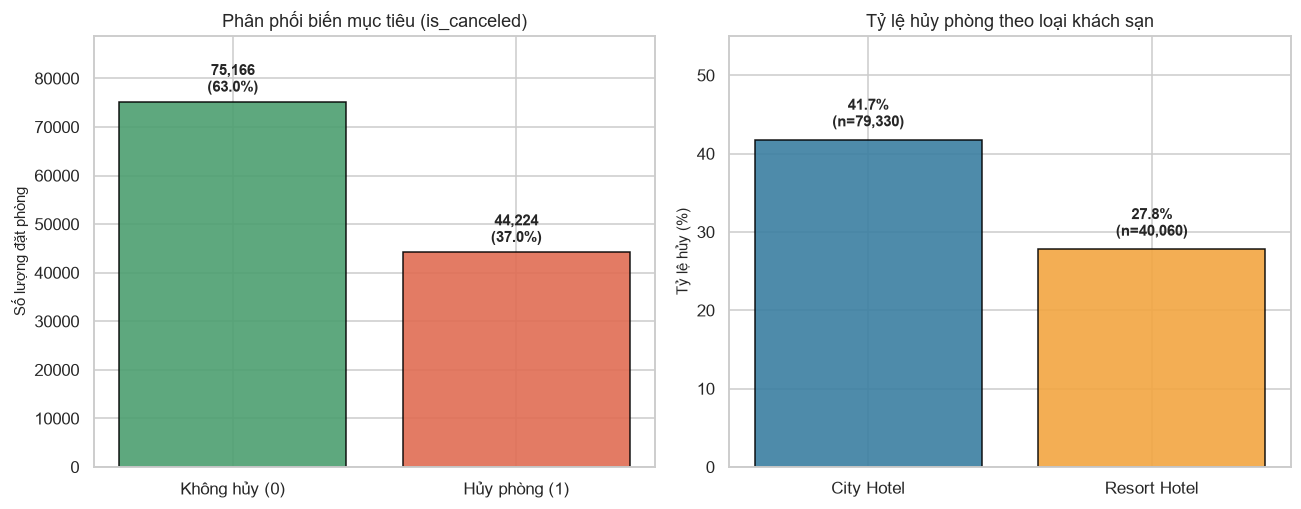

In [5]:
# Biểu đồ 01: Phân phối biến mục tiêu (Tổng thể & Theo loại khách sạn)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Panel 1: Overall
counts = df['is_canceled'].value_counts().sort_index()
labels = ['Không hủy (0)', 'Hủy phòng (1)']
colors = ['#4C9F70', '#E06D53']
bars = axes[0].bar(labels, counts.values, color=colors, edgecolor='black', alpha=0.9)
for bar, c in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, c + 1200, f'{c:,}\n({c/len(df)*100:.1f}%)',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('Phân phối biến mục tiêu (is_canceled)')
axes[0].set_ylabel('Số lượng đặt phòng')
axes[0].set_ylim(0, counts.max() * 1.18)

# Panel 2: By hotel type
hotel_ct = df.groupby('hotel')['is_canceled'].agg(['count', 'mean']).reset_index()
bars2 = axes[1].bar(hotel_ct['hotel'], hotel_ct['mean'] * 100, color=['#3B7EA1', '#F2A541'], edgecolor='black', alpha=0.9)
for bar, row in zip(bars2, hotel_ct.itertuples()):
    axes[1].text(bar.get_x() + bar.get_width()/2, row.mean*100 + 1.2,
                 f'{row.mean*100:.1f}%\n(n={row.count:,})', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_title('Tỷ lệ hủy phòng theo loại khách sạn')
axes[1].set_ylabel('Tỷ lệ hủy (%)')
axes[1].set_ylim(0, 55)

plt.tight_layout()
fig.savefig(FIG_DIR / '01_target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

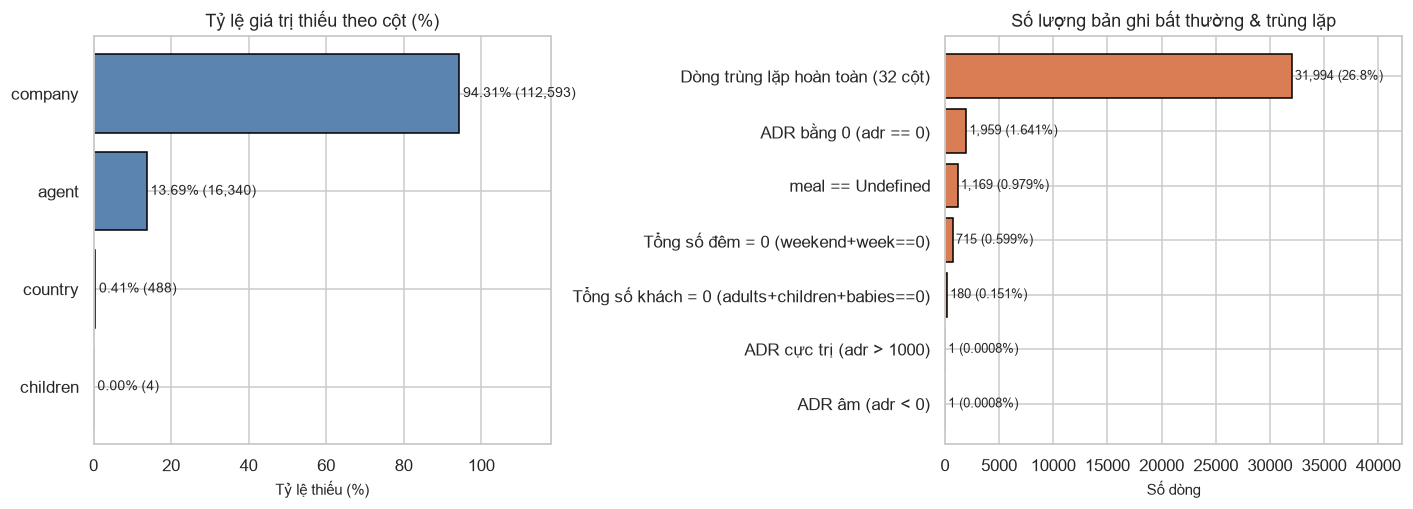

In [6]:
# Biểu đồ 02: Giá trị thiếu & Tổng hợp bất thường chất lượng dữ liệu
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

miss_plot = missing_df[missing_df['missing_count'] > 0].sort_values('missing_pct')
axes[0].barh(miss_plot.index, miss_plot['missing_pct'], color='#5B84B1', edgecolor='black')
for idx, val in enumerate(miss_plot['missing_pct']):
    axes[0].text(val + 1, idx, f'{val:.2f}% ({int(miss_plot["missing_count"].iloc[idx]):,})', va='center', fontsize=9)
axes[0].set_title('Tỷ lệ giá trị thiếu theo cột (%)')
axes[0].set_xlabel('Tỷ lệ thiếu (%)')
axes[0].set_xlim(0, 118)

anom_plot = anomalies.sort_values('Số dòng')
axes[1].barh(anom_plot['Vấn đề'], anom_plot['Số dòng'], color='#D97D54', edgecolor='black')
for idx, row in enumerate(anom_plot.itertuples()):
    axes[1].text(row._2 + 300, idx, f'{row._2:,} ({row._3}%)', va='center', fontsize=8.5)
axes[1].set_title('Số lượng bản ghi bất thường & trùng lặp')
axes[1].set_xlabel('Số dòng')
axes[1].set_xlim(0, anom_plot['Số dòng'].max() * 1.32)

plt.tight_layout()
fig.savefig(FIG_DIR / '02_missing_and_quality.png', dpi=300, bbox_inches='tight')
plt.show()

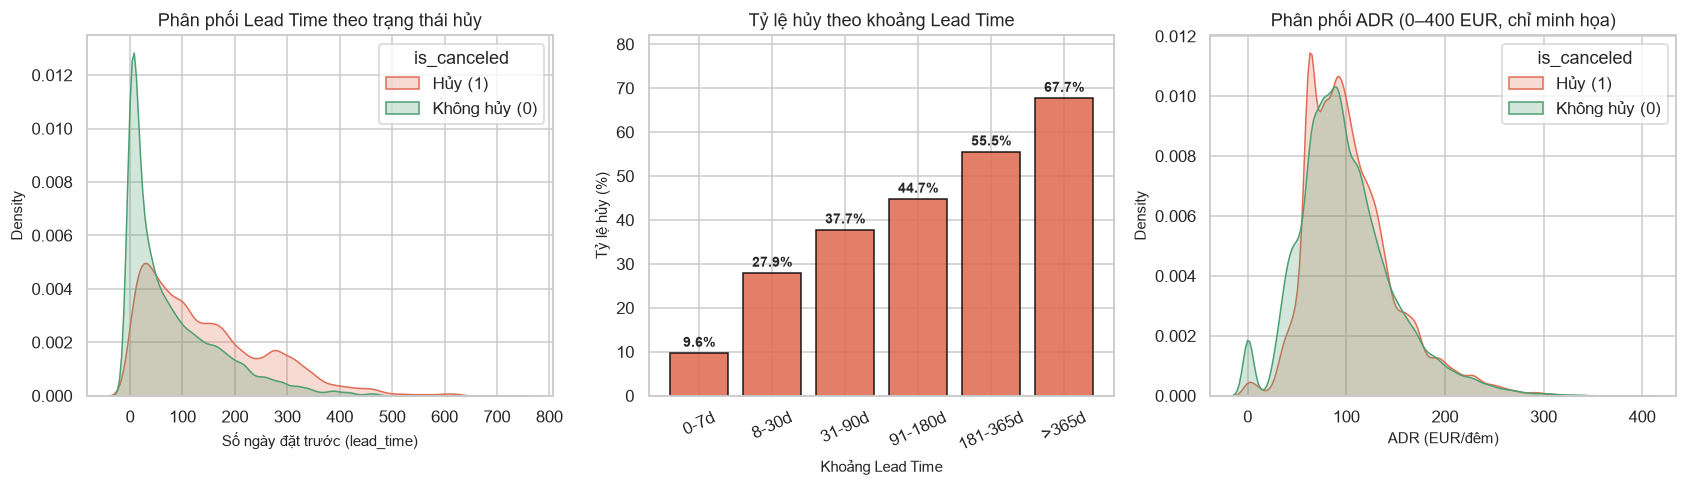

In [7]:
# Biểu đồ 03: Phân phối Lead Time & ADR và Tỷ lệ hủy theo nhóm Lead Time
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))

# Lead time distribution
sns.kdeplot(data=df, x='lead_time', hue='is_canceled', fill=True, common_norm=False,
            palette={0: '#4C9F70', 1: '#E06D53'}, ax=axes[0])
axes[0].set_title('Phân phối Lead Time theo trạng thái hủy')
axes[0].set_xlabel('Số ngày đặt trước (lead_time)')
axes[0].legend(title='is_canceled', labels=['Hủy (1)', 'Không hủy (0)'])

# Cancel rate by lead time bins
lt_bins = pd.cut(df['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 800],
                 labels=['0-7d', '8-30d', '31-90d', '91-180d', '181-365d', '>365d'])
lt_rate = df.groupby(lt_bins, observed=False)['is_canceled'].mean() * 100
bars = axes[1].bar(lt_rate.index.astype(str), lt_rate.values, color='#E06D53', edgecolor='black', alpha=0.88)
for b, v in zip(bars, lt_rate.values):
    axes[1].text(b.get_x() + b.get_width()/2, v + 1.5, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')
axes[1].set_title('Tỷ lệ hủy theo khoảng Lead Time')
axes[1].set_xlabel('Khoảng Lead Time')
axes[1].set_ylabel('Tỷ lệ hủy (%)')
axes[1].set_ylim(0, 82)
axes[1].tick_params(axis='x', rotation=25)

# ADR distribution (clipped 0..400 for visualization only)
adr_vis = df[(df['adr'] >= 0) & (df['adr'] <= 400)]
sns.kdeplot(data=adr_vis, x='adr', hue='is_canceled', fill=True, common_norm=False,
            palette={0: '#4C9F70', 1: '#E06D53'}, ax=axes[2])
axes[2].set_title('Phân phối ADR (0–400 EUR, chỉ minh họa)')
axes[2].set_xlabel('ADR (EUR/đêm)')
axes[2].legend(title='is_canceled', labels=['Hủy (1)', 'Không hủy (0)'])

plt.tight_layout()
fig.savefig(FIG_DIR / '03_lead_time_and_adr.png', dpi=300, bbox_inches='tight')
plt.show()

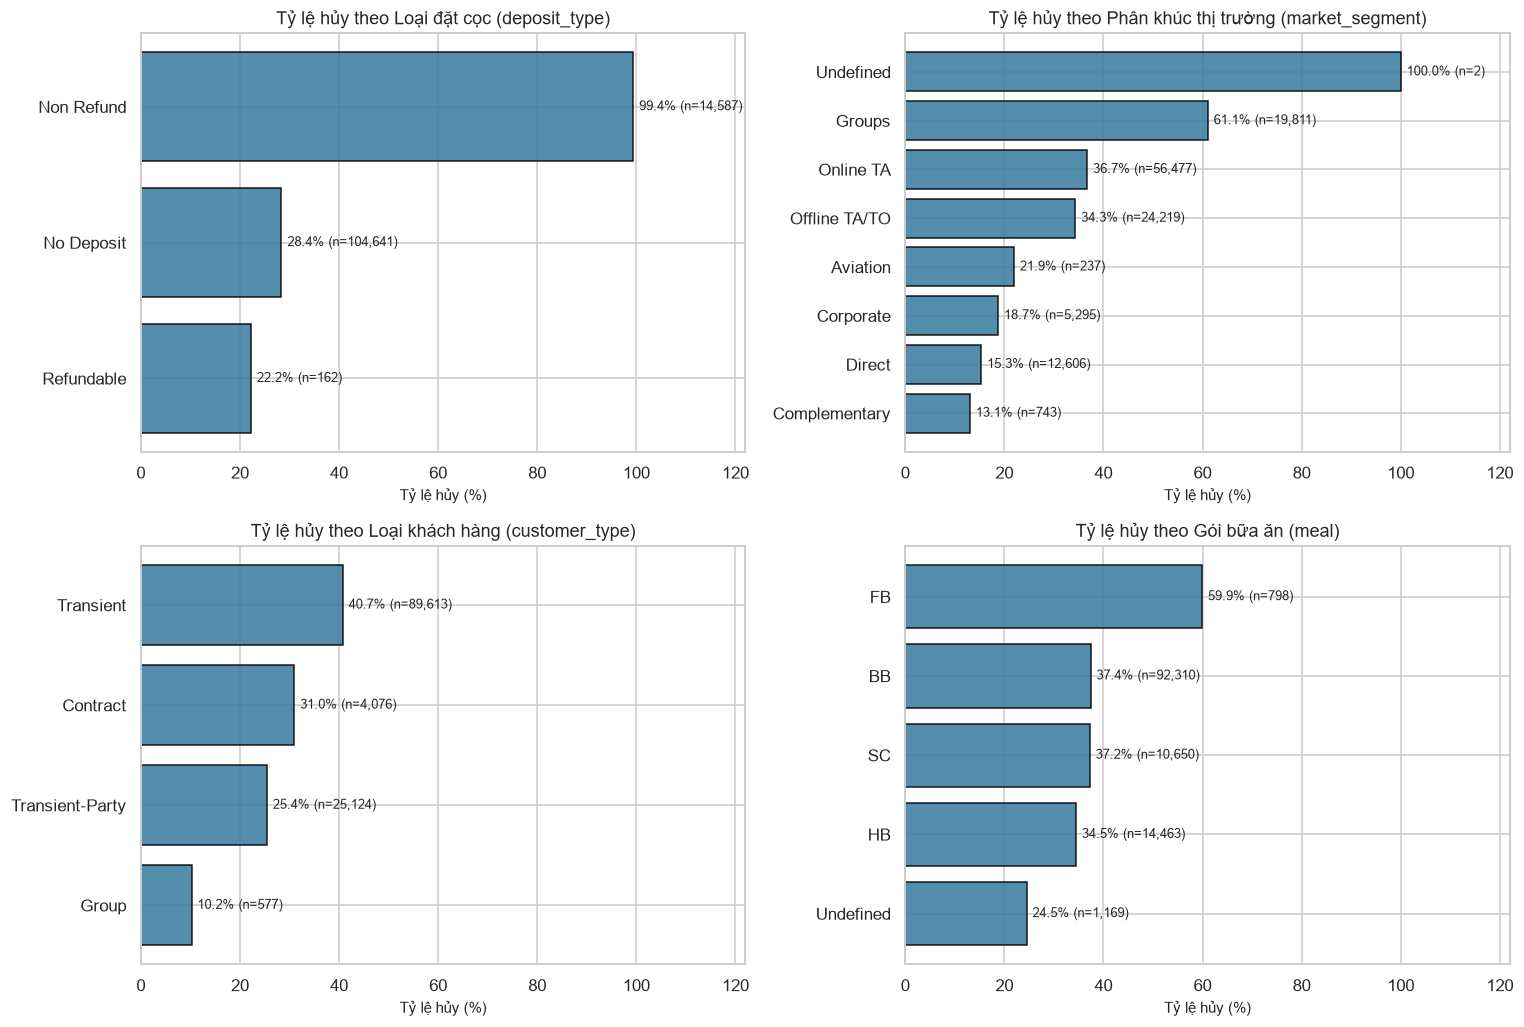

In [8]:
# Biểu đồ 04: Tỷ lệ hủy theo các biến phân loại chính
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
cat_cols_plot = [
    ('deposit_type', 'Loại đặt cọc (deposit_type)'),
    ('market_segment', 'Phân khúc thị trường (market_segment)'),
    ('customer_type', 'Loại khách hàng (customer_type)'),
    ('meal', 'Gói bữa ăn (meal)')
]

for ax, (col, title) in zip(axes.flat, cat_cols_plot):
    grp = df.groupby(col)['is_canceled'].agg(['count', 'mean']).sort_values('mean', ascending=True)
    bars = ax.barh(grp.index.astype(str), grp['mean'] * 100, color='#3B7EA1', edgecolor='black', alpha=0.88)
    for b, row in zip(bars, grp.itertuples()):
        ax.text(row.mean*100 + 1.2, b.get_y() + b.get_height()/2,
                f'{row.mean*100:.1f}% (n={row.count:,})', va='center', fontsize=8.5)
    ax.set_title(f'Tỷ lệ hủy theo {title}')
    ax.set_xlabel('Tỷ lệ hủy (%)')
    ax.set_xlim(0, 122)

plt.tight_layout()
fig.savefig(FIG_DIR / '04_categorical_cancel_rates.png', dpi=300, bbox_inches='tight')
plt.show()

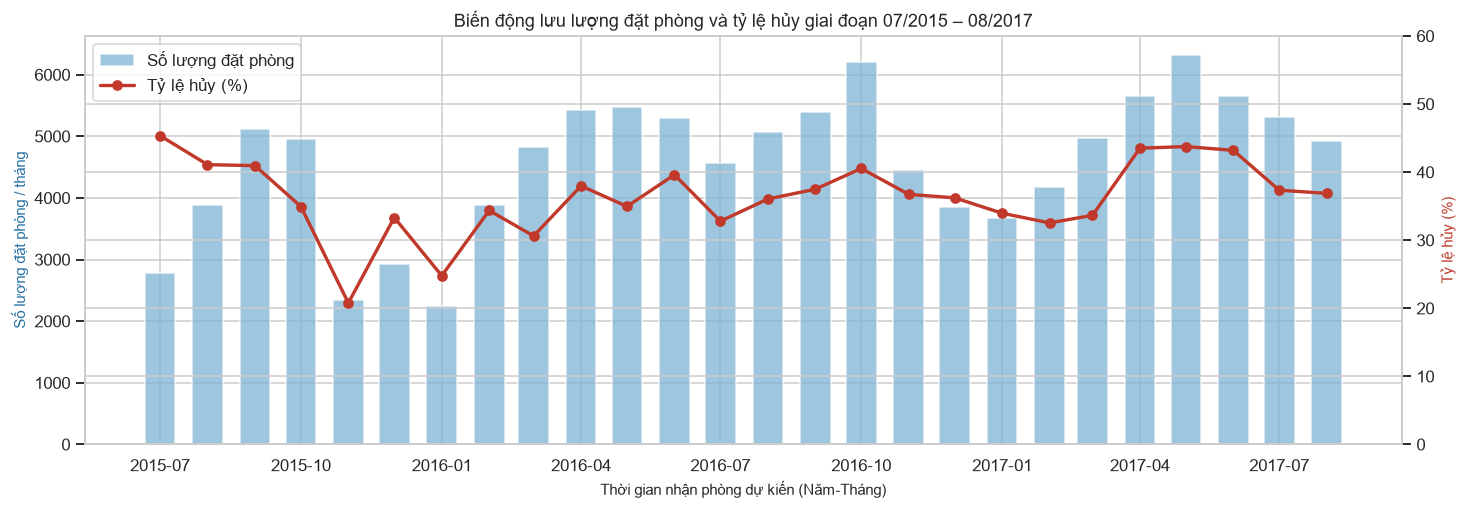

In [9]:
# Biểu đồ 05: Xu hướng lượng đặt phòng và tỷ lệ hủy theo thời gian (2015–2017)
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}
tmp_time = df[['arrival_date_year', 'arrival_date_month', 'is_canceled']].copy()
tmp_time['month_num'] = tmp_time['arrival_date_month'].map(month_map)
tmp_time['ym'] = pd.to_datetime(
    tmp_time['arrival_date_year'].astype(str) + '-' + tmp_time['month_num'].astype(str).str.zfill(2) + '-01'
)
monthly = tmp_time.groupby('ym')['is_canceled'].agg(['count', 'mean']).reset_index()

fig, ax1 = plt.subplots(figsize=(13.5, 4.8))
ax1.bar(monthly['ym'], monthly['count'], width=20, color='#7FB3D5', alpha=0.75, label='Số lượng đặt phòng')
ax1.set_ylabel('Số lượng đặt phòng / tháng', color='#2471A3')
ax1.set_xlabel('Thời gian nhận phòng dự kiến (Năm-Tháng)')

ax2 = ax1.twinx()
ax2.plot(monthly['ym'], monthly['mean'] * 100, color='#C0392B', marker='o', linewidth=2.2, label='Tỷ lệ hủy (%)')
ax2.set_ylabel('Tỷ lệ hủy (%)', color='#C0392B')
ax2.set_ylim(0, 60)

ax1.set_title('Biến động lưu lượng đặt phòng và tỷ lệ hủy giai đoạn 07/2015 – 08/2017')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
fig.savefig(FIG_DIR / '05_temporal_trends.png', dpi=300, bbox_inches='tight')
plt.show()

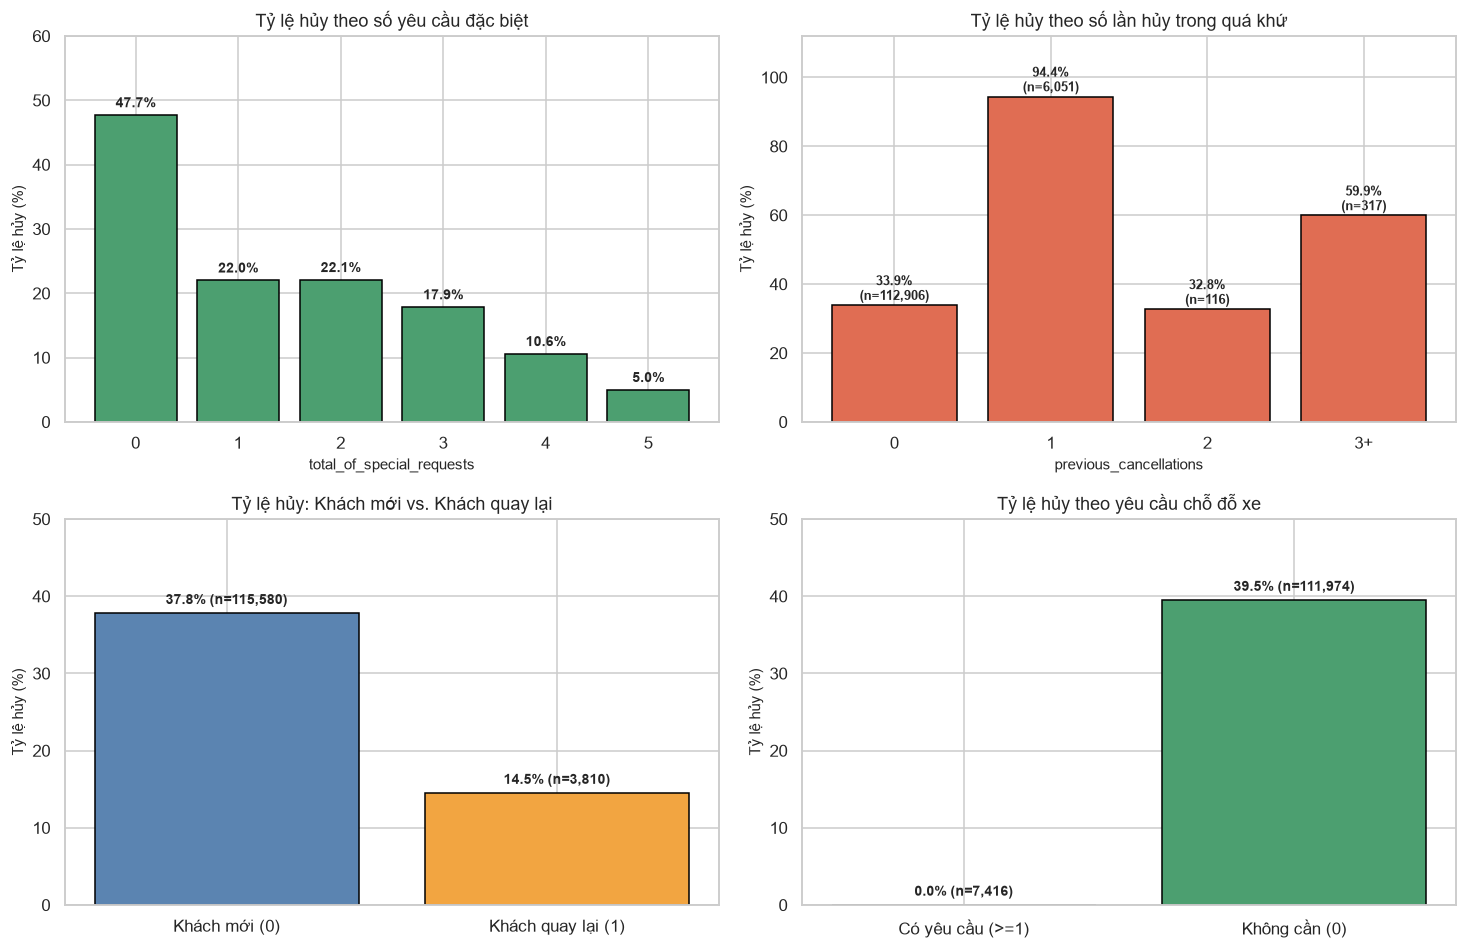

In [10]:
# Biểu đồ 06: Hành vi & lịch sử khách hàng
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.8))

# 1. Special requests
sr = df.groupby('total_of_special_requests')['is_canceled'].agg(['count', 'mean'])
axes[0, 0].bar(sr.index.astype(str), sr['mean']*100, color='#4C9F70', edgecolor='black')
for idx, row in enumerate(sr.itertuples()):
    axes[0, 0].text(idx, row.mean*100 + 1.2, f'{row.mean*100:.1f}%', ha='center', fontsize=9, fontweight='bold')
axes[0, 0].set_title('Tỷ lệ hủy theo số yêu cầu đặc biệt')
axes[0, 0].set_xlabel('total_of_special_requests')
axes[0, 0].set_ylabel('Tỷ lệ hủy (%)')
axes[0, 0].set_ylim(0, 60)

# 2. Previous cancellations (capped at 3+)
pc_bin = df['previous_cancellations'].clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'})
pc = df.groupby(pc_bin)['is_canceled'].agg(['count', 'mean']).reindex(['0', '1', '2', '3+'])
axes[0, 1].bar(pc.index, pc['mean']*100, color='#E06D53', edgecolor='black')
for idx, row in enumerate(pc.itertuples()):
    axes[0, 1].text(idx, row.mean*100 + 1.5, f'{row.mean*100:.1f}%\n(n={row.count:,})', ha='center', fontsize=8.5, fontweight='bold')
axes[0, 1].set_title('Tỷ lệ hủy theo số lần hủy trong quá khứ')
axes[0, 1].set_xlabel('previous_cancellations')
axes[0, 1].set_ylabel('Tỷ lệ hủy (%)')
axes[0, 1].set_ylim(0, 112)

# 3. Repeated guest
rg = df.groupby('is_repeated_guest')['is_canceled'].agg(['count', 'mean'])
axes[1, 0].bar(['Khách mới (0)', 'Khách quay lại (1)'], rg['mean']*100, color=['#5B84B1', '#F2A541'], edgecolor='black')
for idx, row in enumerate(rg.itertuples()):
    axes[1, 0].text(idx, row.mean*100 + 1.2, f'{row.mean*100:.1f}% (n={row.count:,})', ha='center', fontsize=9, fontweight='bold')
axes[1, 0].set_title('Tỷ lệ hủy: Khách mới vs. Khách quay lại')
axes[1, 0].set_ylabel('Tỷ lệ hủy (%)')
axes[1, 0].set_ylim(0, 50)

# 4. Car parking spaces
pk_bin = (df['required_car_parking_spaces'] > 0).map({False: 'Không cần (0)', True: 'Có yêu cầu (>=1)'})
pk = df.groupby(pk_bin)['is_canceled'].agg(['count', 'mean'])
axes[1, 1].bar(pk.index, pk['mean']*100, color=['#D97D54', '#4C9F70'], edgecolor='black')
for idx, row in enumerate(pk.itertuples()):
    axes[1, 1].text(idx, row.mean*100 + 1.2, f'{row.mean*100:.1f}% (n={row.count:,})', ha='center', fontsize=9, fontweight='bold')
axes[1, 1].set_title('Tỷ lệ hủy theo yêu cầu chỗ đỗ xe')
axes[1, 1].set_ylabel('Tỷ lệ hủy (%)')
axes[1, 1].set_ylim(0, 50)

plt.tight_layout()
fig.savefig(FIG_DIR / '06_customer_behavior.png', dpi=300, bbox_inches='tight')
plt.show()

Đã xuất thành công 7 biểu đồ EDA (300 DPI):
  - 01_target_distribution.png (141.0 KB)
  - 02_missing_and_quality.png (208.2 KB)
  - 03_lead_time_and_adr.png (320.7 KB)
  - 04_categorical_cancel_rates.png (361.1 KB)
  - 05_temporal_trends.png (217.6 KB)
  - 06_customer_behavior.png (263.3 KB)
  - 07_correlation_heatmap.png (461.4 KB)


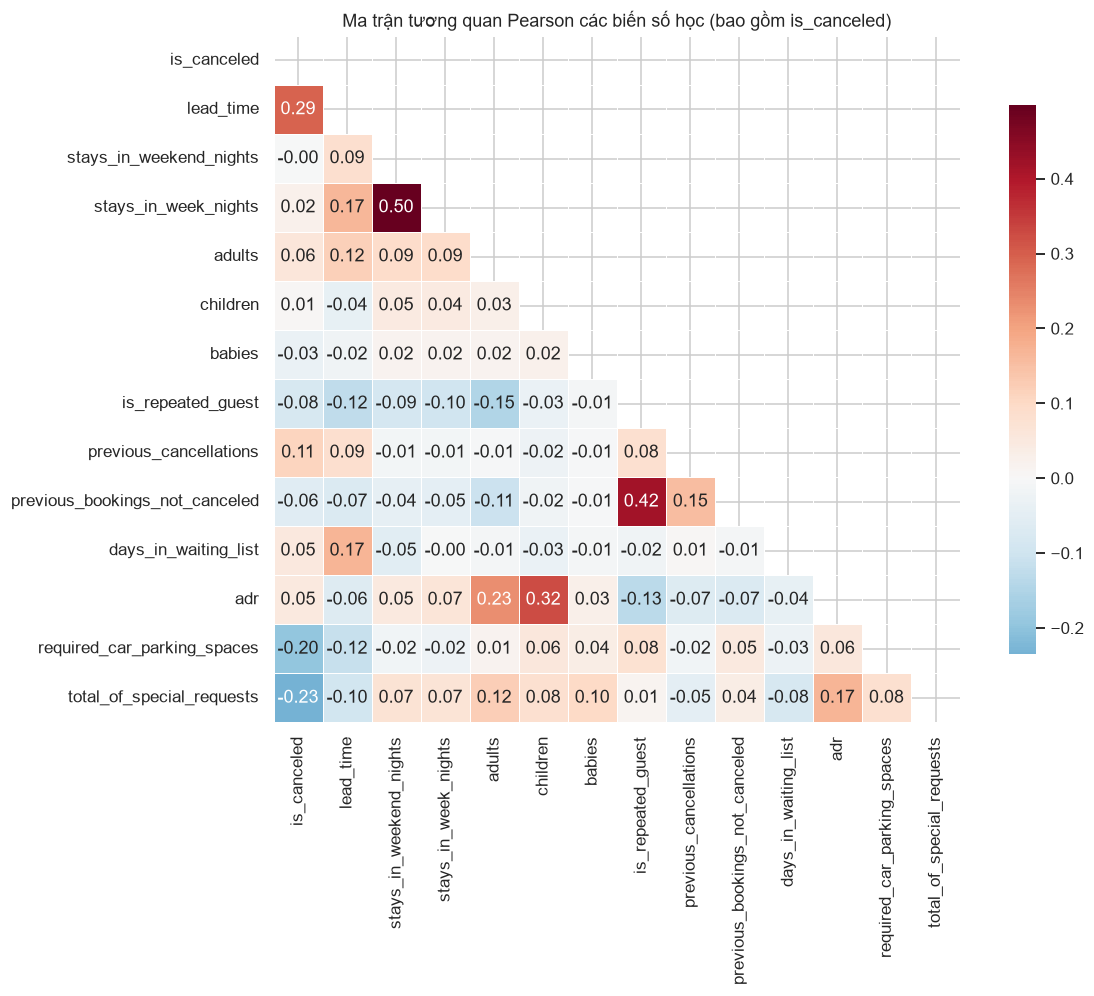

In [11]:
# Biểu đồ 07: Ma trận tương quan giữa các biến số và is_canceled
num_cols = [
    'is_canceled', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
    'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr',
    'required_car_parking_spaces', 'total_of_special_requests'
]
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11.5, 9.2))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Ma trận tương quan Pearson các biến số học (bao gồm is_canceled)')

plt.tight_layout()
fig.savefig(FIG_DIR / '07_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

saved_figs = sorted(FIG_DIR.glob('*.png'))
print(f'Đã xuất thành công {len(saved_figs)} biểu đồ EDA (300 DPI):')
for p in saved_figs:
    print(f'  - {p.name} ({p.stat().st_size/1024:.1f} KB)')